# 3 · Training: linear probe, VPT-deep and full fine-tuning

The training code behind every number in the talk. It follows the paper's recipe (Appendix A, Table 6):

| | linear probe | VPT-deep | full fine-tuning |
| --- | --- | --- | --- |
| trained | head | 12 × 50 prompts + head | every weight + head |
| optimiser | SGD, momentum 0.9 | SGD, momentum 0.9 | AdamW |
| learning rate | base LR × batch / 256, base LR picked on val | same | same |
| schedule | warm-up, then cosine decay | same | same |
| model selection | best validation balanced accuracy | same | same |

Augmentation: random resized crops and flips for skin lesions and blood cells; X-rays get mild crops
only and no flips, because left and right are anatomically meaningful.

**Running it.** The cells below train for real. With `QUICK = True` (the default) they run a short
demonstration on 1,000 images for 12 epochs, about a minute on a laptop GPU (the talk's 1k runs use 100
epochs and a learning-rate sweep). Set
`QUICK = False` to reproduce a full run of the talk (minutes to half an hour each); the commands for all
18 runs are at the end.

In [1]:
import sys, json, time, math
from pathlib import Path
ROOT = Path.cwd().parent            # demo/vpt
sys.path.insert(0, str(ROOT))
import numpy as np, torch
print("torch", torch.__version__, "| CUDA:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

torch 2.11.0+cu128 | CUDA: NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [2]:
# ---- configuration -------------------------------------------------------------------------------
TASK   = "dermamnist"        # dermamnist | bloodmnist | pneumoniamnist
METHOD = "vpt"               # linear | vpt | full
SUBSET = 1000                # training images (0 = the whole train split)
QUICK  = True                # True: 1,000 images, 12 epochs, one learning rate (about a minute)
BATCH  = 32 if METHOD == "full" else 64
EPOCHS = 12 if QUICK else (100 if SUBSET else 30)
SWEEP  = [2.5] if QUICK else ([0.0005, 0.001, 0.005] if METHOD == "full" else ([0.5, 2.5, 10] if METHOD == "linear" else [2.5, 10, 25]))
WEIGHT_DECAY = 0.01 if METHOD == "full" else 1e-4
dev = "cuda"
torch.backends.cuda.matmul.allow_tf32 = True

## Data

The memory-mapped dataset from notebook 2, with the augmentation per modality. Normalisation uses the
base model's own statistics (mean = std = 0.5 for this checkpoint).

In [3]:
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import transforms
from medmnist import INFO

class NpyImages(Dataset):
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform, self.x = images, labels, transform, None
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        if self.x is None:
            self.x = np.load(self.images, mmap_mode="r")
        return self.transform(Image.fromarray(np.asarray(self.x[i])).convert("RGB")), int(self.labels[i])

norm = transforms.Normalize([0.5] * 3, [0.5] * 3)
if TASK == "pneumoniamnist":
    aug = [transforms.RandomResizedCrop(224, scale=(0.8, 1.0), ratio=(0.9, 1.1))]
else:
    aug = [transforms.RandomResizedCrop(224, scale=(0.6, 1.0)), transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip()]
train_tf = transforms.Compose(aug + [transforms.ToTensor(), norm])
eval_tf = transforms.Compose([transforms.ToTensor(), norm])

d = ROOT / "data" / f"{TASK}_224"
sets = {s: NpyImages(d / f"{s}_images.npy", np.load(d / f"{s}_labels.npy"), train_tf if s == "train" else eval_tf) for s in ("train", "val", "test")}
n_train = 1000 if QUICK else SUBSET
if n_train:
    sets["train"] = Subset(sets["train"], np.random.default_rng(0).choice(len(sets["train"]), size=n_train, replace=False).tolist())
CLASSES = [INFO[TASK]["label"][str(i)] for i in range(len(INFO[TASK]["label"]))]
loaders = {k: DataLoader(v, batch_size=BATCH, shuffle=(k == "train"), drop_last=(k == "train"), num_workers=0) for k, v in sets.items()}
print({k: len(v) for k, v in sets.items()}, "|", len(CLASSES), "classes")

{'train': 1000, 'val': 1003, 'test': 2005} | 7 classes


## Evaluation

Accuracy, balanced accuracy (mean per-class recall) and macro one-vs-rest AUC, the MedMNIST metric.

In [4]:
from sklearn.metrics import roc_auc_score

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    probs, ys = [], []
    for x, y in loader:
        with torch.autocast("cuda", dtype=torch.bfloat16):
            probs.append(model(x.to(dev)).float().softmax(-1).cpu())
        ys.append(y)
    p, y = torch.cat(probs).numpy(), torch.cat(ys).numpy()
    pred, n = p.argmax(1), p.shape[1]
    recalls = [(pred[y == c] == c).mean() for c in range(n) if (y == c).any()]
    auc = roc_auc_score(y, p[:, 1]) if n == 2 else roc_auc_score(y, p, multi_class="ovr", average="macro")
    return {"acc": round(100 * float((pred == y).mean()), 2), "bal_acc": round(100 * float(np.mean(recalls)), 2), "auc": round(100 * float(auc), 2)}

## The training loop

The same loop for all three methods; they differ only in which parameters require gradients and in the
optimiser. The checkpoint kept is the one with the best validation balanced accuracy.

In [5]:
import torch.nn as nn
from vpt_model import VPTViT          # the class written out in notebook 1

def train(base_lr, epochs, log=True):
    torch.manual_seed(0)
    model = VPTViT(len(CLASSES), num_prompts=50 if METHOD == "vpt" else 0).to(dev)
    if METHOD == "full":
        for p in model.vit.parameters():
            p.requires_grad = True
    params = [p for p in model.parameters() if p.requires_grad]
    lr = base_lr * BATCH / 256                                    # linear scaling rule, as in the paper
    opt = (torch.optim.AdamW(params, lr=lr, weight_decay=WEIGHT_DECAY) if METHOD == "full"
           else torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=WEIGHT_DECAY))
    per = len(loaders["train"]); steps = epochs * per; warm = max(1, min(10, epochs // 10)) * per
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, steps - warm))))
    keep = model.state_dict if METHOD == "full" else (lambda: {k: v for k, v in model.state_dict().items() if not k.startswith("vit.")})
    best, best_state, history = None, None, []
    for ep in range(epochs):
        model.train(); t0, tot = time.time(), 0.0
        for x, y in loaders["train"]:
            x, y = x.to(dev), y.to(dev)
            with torch.autocast("cuda", dtype=torch.bfloat16):
                loss = nn.functional.cross_entropy(model(x), y)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
            tot += loss.item()
        m = evaluate(model, loaders["val"]); history.append((ep + 1, tot / per, m["bal_acc"]))
        if best is None or m["bal_acc"] > best["bal_acc"]:
            best, best_state = m, {k: v.detach().cpu().clone() for k, v in keep().items()}
        if log:
            print(f"epoch {ep + 1:3d}  train loss {tot / per:.3f}  val {m}  ({time.time() - t0:.1f}s)")
    model.load_state_dict(best_state, strict=False)
    return model, best, history

## Run it

Learning-rate sweep on the validation split (skipped when `QUICK`), then training with the chosen rate,
then one score on the test split.

In [6]:
t_start = time.time()
if len(SWEEP) > 1:
    scores = {lr: train(lr, 20, log=False)[1]["bal_acc"] for lr in SWEEP}
    print("sweep (val balanced accuracy):", scores)
    base_lr = max(scores, key=scores.get)
else:
    base_lr = SWEEP[0]
model, val, history = train(base_lr, EPOCHS)
test = evaluate(model, loaders["test"])
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\n{METHOD} on {TASK}, {len(sets['train'])} training images, base LR {base_lr}: best val {val} | test {test}")
print(f"trainable parameters {trainable:,} | {(time.time() - t_start) / 60:.1f} min")

epoch   1  train loss 1.417  val {'acc': 11.07, 'bal_acc': 14.29, 'auc': 68.55}  (7.6s)


epoch   2  train loss 1.306  val {'acc': 66.9, 'bal_acc': 14.29, 'auc': 74.68}  (7.1s)


epoch   3  train loss 1.175  val {'acc': 66.9, 'bal_acc': 14.29, 'auc': 74.82}  (6.9s)


epoch   4  train loss 1.025  val {'acc': 64.61, 'bal_acc': 26.9, 'auc': 81.55}  (7.9s)


epoch   5  train loss 0.943  val {'acc': 65.4, 'bal_acc': 26.96, 'auc': 84.69}  (7.9s)


...

epoch   9  train loss 0.766  val {'acc': 69.59, 'bal_acc': 24.42, 'auc': 87.97}  (7.7s)


epoch  10  train loss 0.725  val {'acc': 74.68, 'bal_acc': 31.82, 'auc': 87.82}  (7.8s)


epoch  11  train loss 0.698  val {'acc': 73.78, 'bal_acc': 27.87, 'auc': 88.33}  (7.9s)


epoch  12  train loss 0.700  val {'acc': 73.98, 'bal_acc': 28.34, 'auc': 88.4}  (7.9s)



vpt on dermamnist, 1000 training images, base LR 2.5: best val {'acc': 74.68, 'bal_acc': 31.82, 'auc': 87.82} | test {'acc': 72.52, 'bal_acc': 29.43, 'auc': 87.57}
trainable parameters 466,183 | 1.6 min


## The real runs

The talk's numbers come from the full runs, launched from the command line so they survive a closed
notebook. Each writes its weights and a JSON with its metrics to `weights/`. In the order they were run:

```sh
# DermaMNIST: VPT and linear, 1k subset (with LR sweep) and full split
sh run_derma.sh
# VPT for PneumoniaMNIST and BloodMNIST
sh run_queue2.sh
# full fine-tuning on DermaMNIST (AdamW grid 5e-4, 1e-3, 5e-3)
sh run_full.sh
# linear and full fine-tuning on PneumoniaMNIST and BloodMNIST, full split
sh run_queue3.sh
# linear and full fine-tuning on PneumoniaMNIST and BloodMNIST, 1k subset
sh run_queue4.sh
```

Each of those calls `train.py`, which contains the same code as this notebook, for example:

```sh
python train.py --data dermamnist --method vpt --subset 1000 --sweep 2.5 10 25 --epochs 100
python train.py --data dermamnist --method full --batch 32 --wd 0.01 --base-lr 0.001 --epochs 30
```

Below, the validation curves of the actual 1k runs on DermaMNIST, read from their logs.

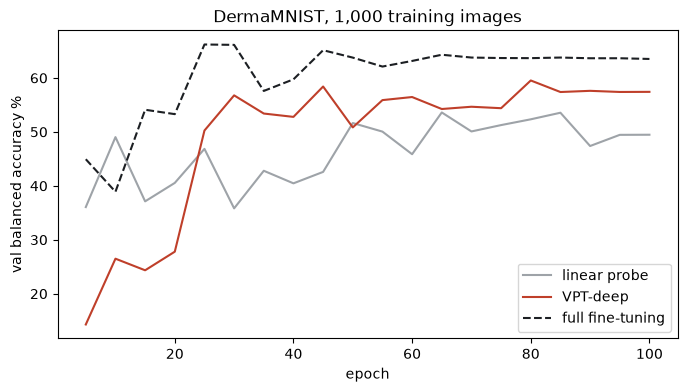

In [7]:
import re, matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
for name, log, color in [("linear probe", "derma_linear_1k.log", "#9EA3A8"), ("VPT-deep", "derma_vpt_1k.log", "#BF3F2A"), ("full fine-tuning", "derma_full_1k.log", "#1C1F23")]:
    path = ROOT / "logs" / log
    if not path.exists():
        continue
    pts = [(int(m.group(1)), float(m.group(2))) for m in re.finditer(r"ep\s+(\d+).*?'bal_acc': ([\d.]+)", path.read_text(errors="ignore"))]
    ax.plot(*zip(*pts), label=name, color=color, ls="--" if "full" in name else "-")
ax.set_xlabel("epoch"); ax.set_ylabel("val balanced accuracy %"); ax.set_title("DermaMNIST, 1,000 training images"); ax.legend(); plt.show()